In [1]:
# Packages
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2_contingency, chi2
import statsmodels.api as sm
import statsmodels.formula.api as smf

plt.style.use("bmh")

### 1. Wykonaj analizę struktury z podziałem na cechy ciągłe i skokowe oraz graficzną oceną wyników badania. W ocenie uwzględnij zakres oraz rozkład braków danych.

In [2]:
# Ścieżka do zbioru danych kb06.csv
data_path='kb06.csv'
#Import danych z csv
df=pd.read_csv(data_path)

In [3]:
# Kształt zbioru danych
print('Liczba obserwacji: ' + str(df.shape[0]))
print('Liczba zmiennych: ' + str(df.shape[1]))

Liczba obserwacji: 11304
Liczba zmiennych: 6


In [4]:
# Kilka pierwszych obserwacji
df.head()

,age,education,house_loan,poutcome,contact,y_newdeposit
0,41,secondary,yes,unknown,0,0.0
1,53,secondary,yes,unknown,0,NaN
2,58,unknown,yes,unknown,0,0.0
3,57,secondary,yes,unknown,0,0.0
4,57,primary,yes,unknown,0,0.0


In [5]:
# Rodzaje zmiennych
print("Rodzaje zmiennych:")
df.dtypes

Rodzaje zmiennych:


age               int64
education           str
house_loan          str
poutcome            str
contact           int64
y_newdeposit    float64
dtype: object

In [6]:
# Podział zmiennych na ciągłe i skokowe
cont_var = ['age']
print("Zmienne ciągłe:")
print(cont_var)

disc_var = [
    'education',
    'house_loan',
    'poutcome',
    'contact',
    'y_newdeposit'
]
print("Zmienne skokowe:")
print(disc_var)

Zmienne ciągłe:
['age']
Zmienne skokowe:
['education', 'house_loan', 'poutcome', 'contact', 'y_newdeposit']


In [7]:
# Statystyki zmiennej ciągłej
df[cont_var].describe().round(2)

,age
count,11304.00
mean,41.00
std,10.67
min,18.00
25%,33.00
50%,39.00
75%,49.00
max,92.00


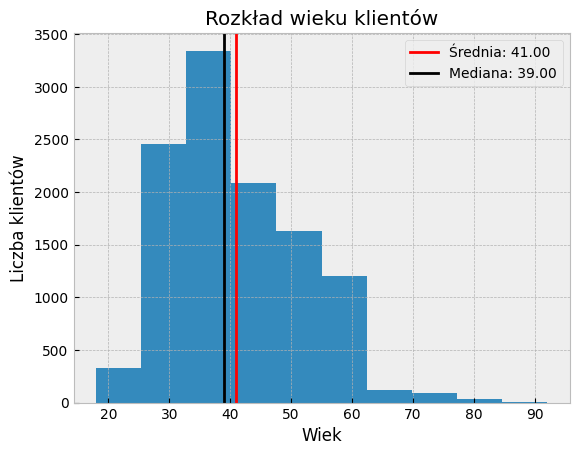

In [8]:
# Rozkład wieku klientów
plt.hist(df['age'])
plt.axvline(df['age'].mean(), color='red', 
           label=f"Średnia: {df['age'].mean():.2f}")
plt.axvline(df['age'].median(), color='black',
            label=f"Mediana: {df['age'].median():.2f}")
plt.title('Rozkład wieku klientów')
plt.xlabel('Wiek')
plt.ylabel('Liczba klientów')
plt.legend()
plt.show()

In [9]:
# Statystyki dla zmiennych skokowych
for var in disc_var:
    print(f'\nZmienna: {var}')

    print(pd.DataFrame({
        'Liczebność': df[var].value_counts(dropna=False),
        'Udział (%)': df[var].value_counts(normalize=True, dropna=False) * 100
    }).round(2))


Zmienna: education
           Liczebność  Udział (%)
education                        
secondary        5788       51.20
tertiary         3337       29.52
primary          1712       15.15
unknown           467        4.13

Zmienna: house_loan
            Liczebność  Udział (%)
house_loan                        
yes               6340       56.09
no                4964       43.91

Zmienna: poutcome
          Liczebność  Udział (%)
poutcome                        
unknown         9189       81.29
failure         1263       11.17
other            482        4.26
success          370        3.27

Zmienna: contact
         Liczebność  Udział (%)
contact                        
1              7369       65.19
0              3198       28.29
2               737        6.52

Zmienna: y_newdeposit
              Liczebność  Udział (%)
y_newdeposit                        
0.0                 9332       82.55
NaN                 1418       12.54
1.0                  554        4.90


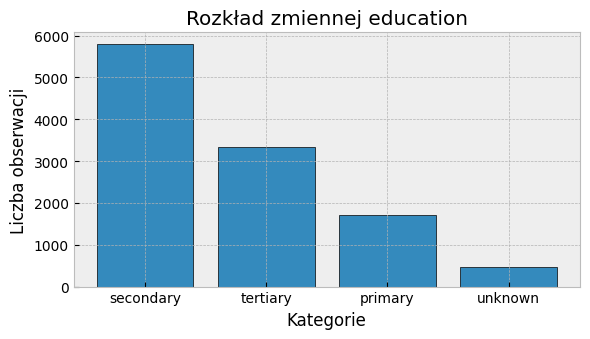

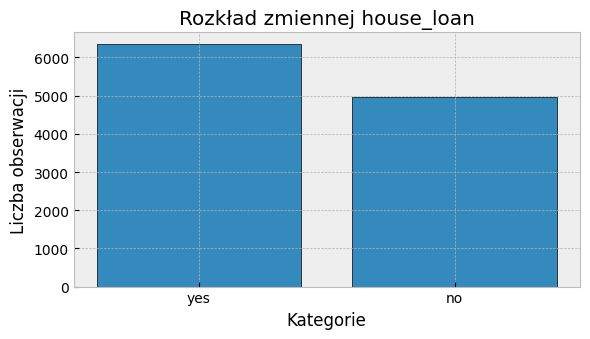

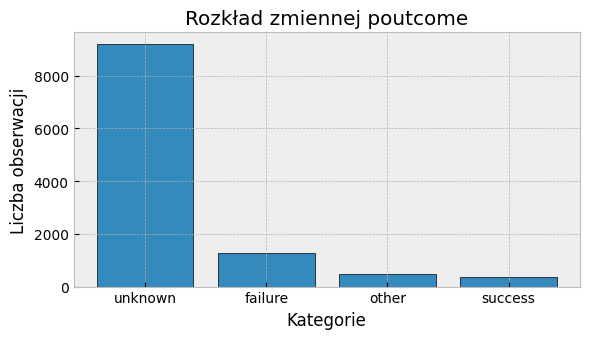

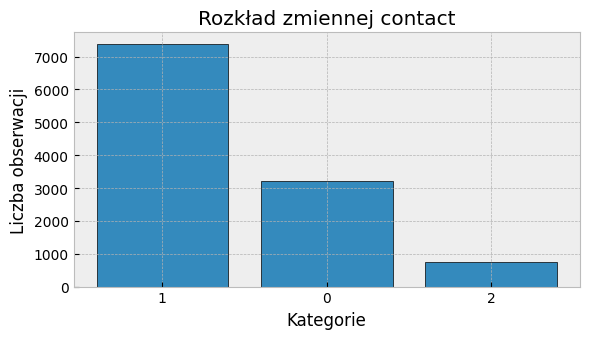

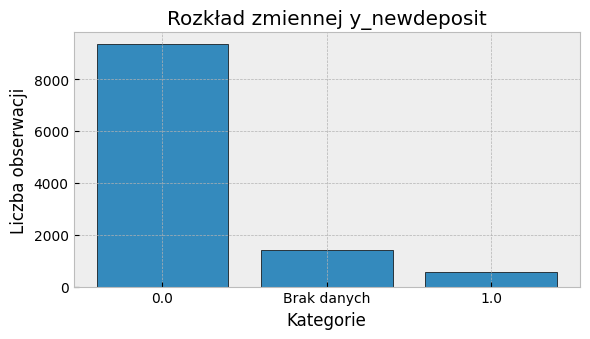

In [10]:
# Wykresy zmiennych skokowych
for var in disc_var:
    counts = df[var].fillna('Brak danych').value_counts()

    plt.figure(figsize=(6, 3.5))
    plt.bar(counts.index.astype(str), counts.values, edgecolor='black')

    plt.title(f'Rozkład zmiennej {var}')
    plt.xlabel('Kategorie')
    plt.ylabel('Liczba obserwacji')

    plt.tight_layout()
    plt.show()

In [11]:
# Braki danych
missing_val = df.isna().sum()
print(missing_val)

age                0
education          0
house_loan         0
poutcome           0
contact            0
y_newdeposit    1418
dtype: int64


In [12]:
# Analiza braków dla y_newdeposit
target_summary  = pd.DataFrame({
    'Liczebność': df['y_newdeposit'].value_counts(dropna=False),
    'Udział (%)': df['y_newdeposit'].value_counts(dropna=False, normalize=True) * 100
})

target_summary.index = target_summary.index.map({
    0: 'Brak zakupu (0)',
    1: 'Zakup (1)'
}).fillna('Brak danych')

print(target_summary)

                 Liczebność  Udział (%)
y_newdeposit                           
Brak zakupu (0)        9332   82.554848
Brak danych            1418   12.544232
Zakup (1)               554    4.900920


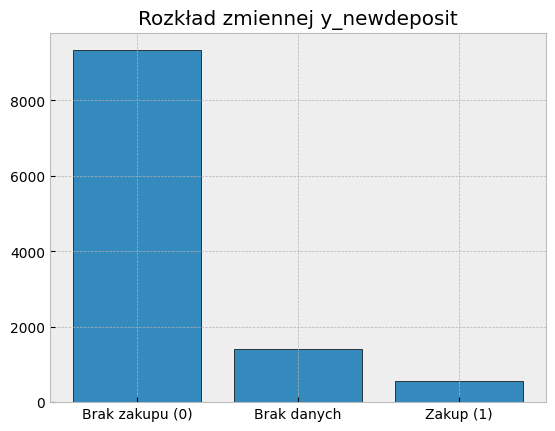

In [13]:
#Wykres zmiennej y_newdeposit
plt.bar(target_summary.index, target_summary.iloc[:, 0], edgecolor='black')
plt.title("Rozkład zmiennej y_newdeposit")
plt.show()

In [14]:
# Wyniki kampanii marketingowej
# Kopia danych do analizy graficznej
df_plot = df.copy()

# Czytelne etykiety
df_plot['y_newdeposit'] = df_plot['y_newdeposit'].map({
    0: 'Brak zakupu',
    1: 'Zakup'
}).fillna('Brak danych')

# Liczebność poszczególnych wyników w grupach komunikacji
tabela_liczebnosci = pd.crosstab(
    df_plot['contact'],
    df_plot['y_newdeposit']
)

tabela_liczebnosci = tabela_liczebnosci[
    ['Zakup', 'Brak zakupu', 'Brak danych']
]

print(tabela_liczebnosci)

y_newdeposit  Zakup  Brak zakupu  Brak danych
contact                                      
0               113         2624          461
1               383         6271          715
2                58          437          242


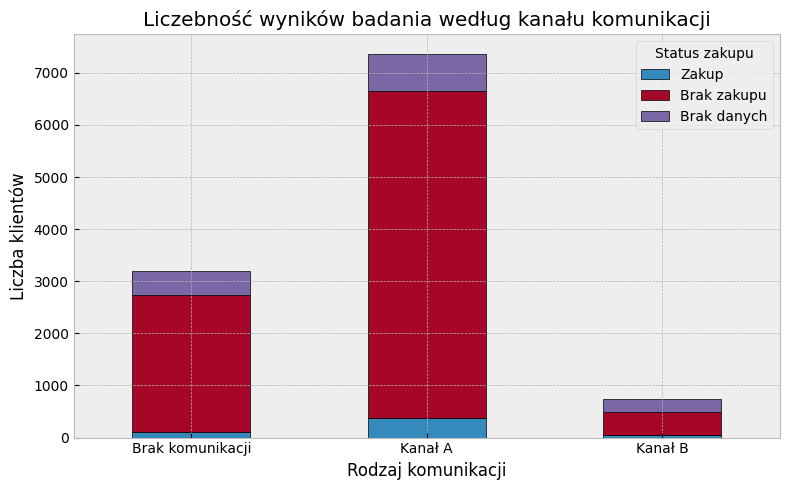

In [15]:
# Wykres liczebności wyników badania
tabela_liczebnosci.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Liczebność wyników badania według kanału komunikacji')
plt.xlabel('Rodzaj komunikacji')
plt.ylabel('Liczba klientów')
plt.xticks(
    ticks=[0, 1, 2],
    labels=['Brak komunikacji', 'Kanał A', 'Kanał B'],
    rotation=0
)
plt.legend(title='Status zakupu')
plt.tight_layout()
plt.show()

In [16]:
# Tabela udziałów procentowych w grupach komunikacji
tabela_wynikow = pd.crosstab(
    df_plot['contact'],
    df_plot['y_newdeposit'],
    normalize='index'
) * 100

# Uporządkowanie kategorii
tabela_wynikow = tabela_wynikow[
    ['Zakup', 'Brak zakupu', 'Brak danych']
]
print(tabela_wynikow)

y_newdeposit     Zakup  Brak zakupu  Brak danych
contact                                         
0             3.533458    82.051282    14.415260
1             5.197449    85.099742     9.702809
2             7.869742    59.294437    32.835821


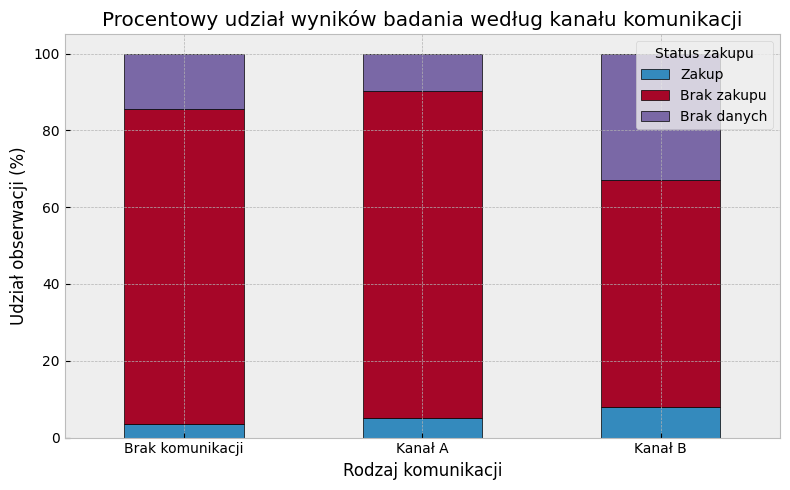

In [17]:
# Wykres skumulowany
tabela_wynikow.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Procentowy udział wyników badania według kanału komunikacji')
plt.xlabel('Rodzaj komunikacji')
plt.ylabel('Udział obserwacji (%)')
plt.xticks(
    ticks=[0, 1, 2],
    labels=['Brak komunikacji', 'Kanał A', 'Kanał B'],
    rotation=0
)
plt.legend(title='Status zakupu')
plt.tight_layout()
plt.show()

### 2. Oceń zależność pomiędzy prawdopodobieństwem braku danych a pozostałymi cechami, aby wskazać czy istnieją takie cechy, za pomocą których możemy dokonać korekty oszacowań stosując imputację danych.

In [18]:
# Wskaźnik braku wyniku zakupu: 1 = brak, 0 = wynik znany

df_m = df.copy()
df_m['missing_y'] = df_m['y_newdeposit'].isna().astype(int)
print(f"Braki y_newdeposit: {df_m['missing_y'].sum()} z {len(df_m)} ({df_m['missing_y'].mean():.2%})")

Braki y_newdeposit: 1418 z 11304 (12.54%)


In [19]:
# Odsetek braków według cech skokowych oraz testy niezależności chi-kwadrat
cat_vars = ['contact', 'education', 'house_loan', 'poutcome']
missing_rates = {}

for var in cat_vars:
    tab = pd.crosstab(df_m[var], df_m['missing_y']).reindex(columns=[0, 1], fill_value=0)
    missing_rates[var] = (100 * tab[1] / tab.sum(axis=1)).round(2)
    chi2_stat, p, _, _ = chi2_contingency(tab)
    print(f"\n{var} | test chi2: p = {p:.4g}")
    print(pd.DataFrame({'Liczba klientów': tab.sum(axis=1),
                        'Braki (n)': tab[1], 'Braki (%)': missing_rates[var]}))


contact | test chi2: p = 8.769e-75
         Liczba klientów  Braki (n)  Braki (%)
contact                                       
0                   3198        461      14.42
1                   7369        715       9.70
2                    737        242      32.84

education | test chi2: p = 0.0006324
           Liczba klientów  Braki (n)  Braki (%)
education                                       
primary               1712        213      12.44
secondary             5788        696      12.02
tertiary              3337        422      12.65
unknown                467         87      18.63

house_loan | test chi2: p = 1.986e-15
            Liczba klientów  Braki (n)  Braki (%)
house_loan                                       
no                     4964        762      15.35
yes                    6340        656      10.35

poutcome | test chi2: p = 5.999e-86
          Liczba klientów  Braki (n)  Braki (%)
poutcome                                       
failure              1263

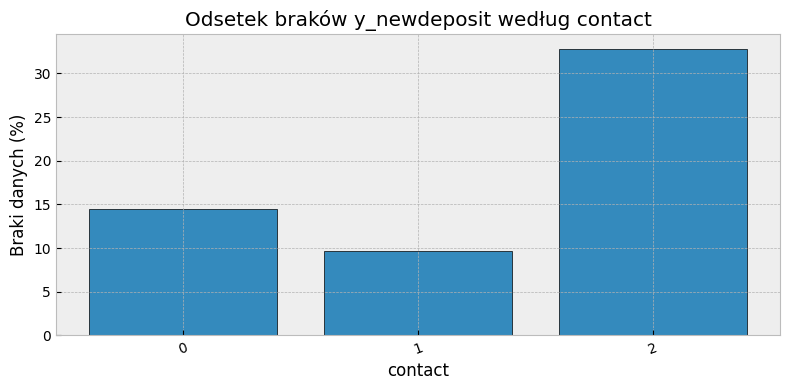

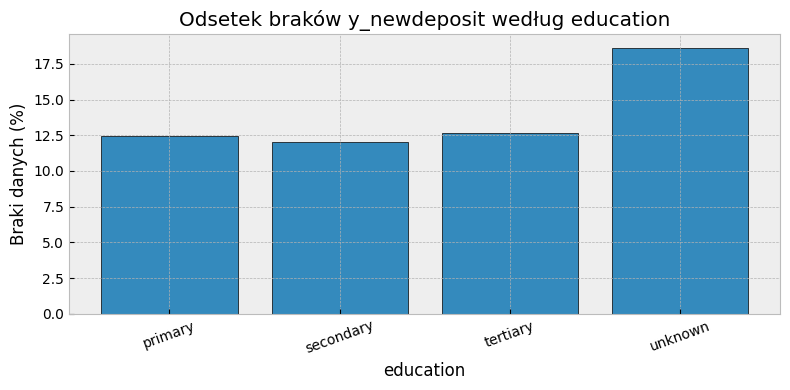

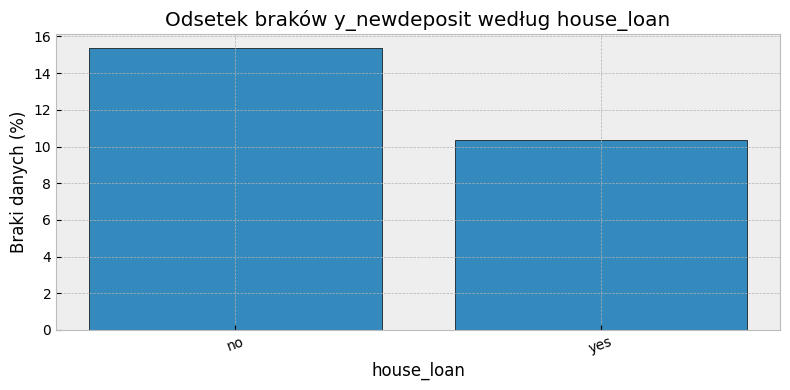

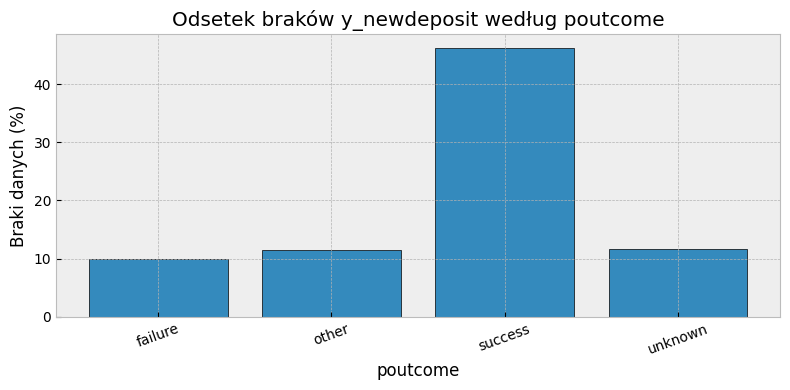

In [20]:
# Udział braków danych w poszczególnych grupach
for var in cat_vars:
    rates = missing_rates[var]
    plt.figure(figsize=(8, 4))
    plt.bar(rates.index.astype(str), rates.values, edgecolor='black')
    plt.title(f'Odsetek braków y_newdeposit według {var}')
    plt.ylabel('Braki danych (%)')
    plt.xlabel(var)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

           count   mean  median    std
missing_y                             
0           9886  40.84    39.0  10.36
1           1418  42.13    40.0  12.56


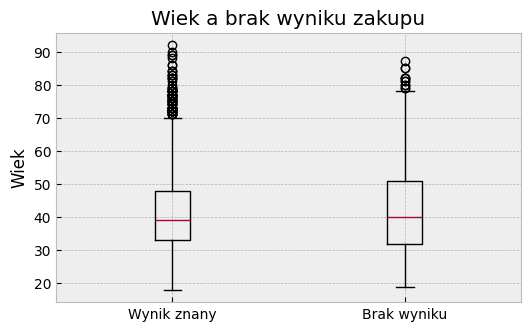

In [21]:
# Wiek a występowanie braków (porównanie średnich)
print(df_m.groupby('missing_y')['age'].agg(['count', 'mean', 'median', 'std']).round(2))

plt.figure(figsize=(6, 3.5))
plt.boxplot([df_m.loc[df_m['missing_y'] == 0, 'age'],
             df_m.loc[df_m['missing_y'] == 1, 'age']],
            tick_labels=['Wynik znany', 'Brak wyniku'])
plt.title('Wiek a brak wyniku zakupu')
plt.ylabel('Wiek')
plt.show()

In [22]:
# Regresja logistyczna: prawdopodobieństwo braku danych a cechy klientów
formula_m = ('missing_y ~ age + C(contact) + C(education)'
             ' + C(house_loan) + C(poutcome)')
model_m = smf.glm(formula_m, data=df_m, family=sm.families.Binomial()).fit()

wyniki_m = pd.DataFrame({'OR': np.exp(model_m.params),
                         'p-value': model_m.pvalues}).round(4)
print(wyniki_m)

# Globalny test modelu względem modelu bez predyktorów
model_0 = smf.glm('missing_y ~ 1', data=df_m, family=sm.families.Binomial()).fit()
lr = 2 * (model_m.llf - model_0.llf)
p_global = chi2.sf(lr, model_m.df_model)
print(f"\nTest globalny: LR = {lr:.2f}, p = {p_global:.4g}")

                               OR  p-value
Intercept                  0.2716   0.0000
C(contact)[T.1]            0.4532   0.0000
C(contact)[T.2]            2.3078   0.0000
C(education)[T.secondary]  1.0684   0.4551
C(education)[T.tertiary]   1.1357   0.1886
C(education)[T.unknown]    1.4985   0.0056
C(house_loan)[T.yes]       0.6528   0.0000
C(poutcome)[T.other]       1.0619   0.7334
C(poutcome)[T.success]     7.2038   0.0000
C(poutcome)[T.unknown]     0.8365   0.0956
age                        0.9976   0.3968

Test globalny: LR = 646.84, p = 1.605e-132


### 3. Oszacuj model regresji logistycznej przy założeniach MCAR oraz MAR. Tekst pracy powinien zawierać specyfikację modelu imputacyjnego.

In [23]:
from scipy.stats import t

dane = df.copy()

# Utworzenie zmiennych zero-jedynkowych dla kanałów komunikacji.

dane["contact_A"] = (dane["contact"] == 1).astype(int)
dane["contact_B"] = (dane["contact"] == 2).astype(int)


#1. IMPUTACJA I MODEL MCAR
# Zakładamy, że występowanie braków jest całkowicie losowe.
# Brakujące wartości newdeposit uzupełniamy poprzez losowanie z rozkładu empirycznego zaobserwowanych wartości 0 i 1.

np.random.seed(121854)

wartosci_obserwowane = dane["y_newdeposit"].dropna().values

# Liczba imputowanych zbiorów
m = 20

zbiory_mcar = []

# 20 niezależnych imputacji
for i in range(m):
    dane_imp = dane.copy()
    braki = dane_imp["y_newdeposit"].isna()
    dane_imp.loc[braki, "y_newdeposit"] = np.random.choice(
        wartosci_obserwowane,
        size=braki.sum(),
        replace=True
    )

    zbiory_mcar.append(dane_imp)

# Kanał 0 jest kategorią referencyjną dla CONTACT.
# Dla HOUSING_LOAN kategorią referencyjną jest Yes.
# Dla POUTCOME kategorią referencyjną jest Unknown.

house_ref = "yes"
poutcome_ref = "unknown"

formula_model = (
    "y_newdeposit ~ contact_A + contact_B + age + "
    f"C(house_loan, Treatment(reference={house_ref!r})) + "
    f"C(poutcome, Treatment(reference={poutcome_ref!r}))"
)

modele_mcar = []

# Oszacowanie modelu dla każdego zbioru
for zbior in zbiory_mcar:
    model = smf.logit(
        formula=formula_model,
        data=zbior
    ).fit(disp=False, maxiter=200)

    modele_mcar.append(model)


# 2. IMPUTACJA I MODEL MAR
# Zakładamy, że prawdopodobieństwo wystąpienia braków zależy od innych zaobserwowanych zmiennych.
# W modelu imputacyjnym uwzględniamy: AGE, CONTACT, HOUSING_LOAN oraz POUTCOME.
# Brakujące wartości zmiennej newdeposit przewidujemy za pomocą regresji logistycznej.

braki_obs = dane["y_newdeposit"].notna()
braki_brak = dane["y_newdeposit"].isna()


X_mar = pd.get_dummies(
    dane[["age", "contact", "house_loan", "poutcome"]],
    columns=["contact", "house_loan", "poutcome"],
    drop_first=True,
    dtype=float
)

X_mar = sm.add_constant(X_mar, has_constant="add")

X_obs = X_mar.loc[braki_obs]
y_obs = dane.loc[braki_obs, "y_newdeposit"].astype(int)

# Oszacowanie regresji logistycznej na obserwacjach bez braków
model_imputacyjny = sm.Logit(y_obs, X_obs).fit(
    disp=False,
    maxiter=200
)

beta_hat = model_imputacyjny.params
cov_beta = model_imputacyjny.cov_params()

X_braki = X_mar.loc[braki_brak]

zbiory_mar = []

# 20 niezależnych imputacji
np.random.seed(121854)

for i in range(m):
    dane_imp = dane.copy()
    if braki_brak.sum() > 0:

        # Losowanie parametrów z rozkładu uwzględniającego niepewność estymacji modelu imputacyjnego.
        beta_losowe = np.random.multivariate_normal(
            mean=beta_hat.values,
            cov=cov_beta.values
        )

        # Obliczenie prawdopodobieństwa zakupu dla brakujących obserwacji na podstawie modelu logistycznego.
        prawdopodobienstwo = 1 / (
            1 + np.exp(-(X_braki.values @ beta_losowe))
        )

        # Losowanie wartości 0 lub 1 z rozkładu Bernoulliego.
        losowe_wartosci = np.random.binomial(
            n=1,
            p=prawdopodobienstwo
        )

        dane_imp.loc[braki_brak, "y_newdeposit"] = losowe_wartosci


    zbiory_mar.append(dane_imp)


modele_mar = []

for zbior in zbiory_mar:
    model = smf.logit(
        formula=formula_model,
        data=zbior
    ).fit(disp=False, maxiter=200)

    modele_mar.append(model)


# 3. ŁĄCZENIE WYNIKÓW – REGUŁY RUBINA
# Obliczamy:
# Q_bar – średnią wartość oszacowanego parametru,
# U_bar – średnią wariancję wewnątrz imputacji,
# B     – wariancję pomiędzy imputacjami,
# T     – całkowitą wariancję oszacowania.

def laczenie_wynikow(modele, nazwa_parametru):

    # Oszacowania parametru z poszczególnych modeli
    Q = np.array([
        model.params[nazwa_parametru]
        for model in modele
    ])

    # Wariancje oszacowań z poszczególnych modeli
    U = np.array([
        model.cov_params().loc[nazwa_parametru, nazwa_parametru]
        for model in modele
    ])

    # Liczba imputacji
    m = len(Q)

    # Średnie oszacowanie parametru
    Q_bar = np.mean(Q)

    # Średnia wariancja wewnątrz imputacji
    U_bar = np.mean(U)

    # Wariancja pomiędzy imputacjami
    B = np.var(Q, ddof=1)

    # Całkowita wariancja wg reguł Rubina
    T = U_bar + (1 + 1/m) * B

    # Błąd standardowy
    SE = np.sqrt(T)

    # Stopnie swobody wg przybliżenia Rubina
    if B < 1e-12:
        df = np.inf
    else:
        r = ((1 + 1/m) * B) / U_bar
        df = (m - 1) * (1 + 1/r)**2

    # Statystyka testowa
    t_stat = Q_bar / SE

    # Wartość p
    p_value = 2 * t.sf(abs(t_stat), df)

    # Przedział ufności 95%
    if np.isinf(df):
        wartosc_krytyczna = 1.96
    else:
        wartosc_krytyczna = t.ppf(0.975, df)

    CI_dolny = Q_bar - wartosc_krytyczna * SE
    CI_gorny = Q_bar + wartosc_krytyczna * SE

    return {
        "Oszacowanie": Q_bar,
        "SE": SE,
        "Statystyka": t_stat,
        "df": df,
        "p_value": p_value,
        "CI_dolny": CI_dolny,
        "CI_gorny": CI_gorny
    }


# Funkcja tworząca tabelę połączonych wyników
def tabela_wynikow(modele):

    parametry = modele[0].params.index

    wyniki = []

    for parametr in parametry:

        wynik = laczenie_wynikow(modele, parametr)

        wyniki.append({
            "Parametr": parametr,
            **wynik
        })

    return pd.DataFrame(wyniki)


# Połączenie wyników MCAR
wyniki_mcar = tabela_wynikow(modele_mcar)

# Połączenie wyników MAR
wyniki_mar = tabela_wynikow(modele_mar)

print("\nWYNIKI MODELU MCAR:")
print(wyniki_mcar.round(4).to_string(index=False))

print("\nWYNIKI MODELU MAR:")
print(wyniki_mar.round(4).to_string(index=False))


WYNIKI MODELU MCAR:
                                              Parametr  Oszacowanie     SE  Statystyka        df  p_value  CI_dolny  CI_gorny
                                             Intercept      -3.1956 0.1890    -16.9085  837.1204   0.0000   -3.5665   -2.8246
       C(house_loan, Treatment(reference='yes'))[T.no]       0.4475 0.0920      4.8646 3714.8418   0.0000    0.2672    0.6279
C(poutcome, Treatment(reference='unknown'))[T.failure]      -0.0122 0.1581     -0.0772 1554.8915   0.9385   -0.3224    0.2980
  C(poutcome, Treatment(reference='unknown'))[T.other]       0.2636 0.2138      1.2326 1217.8671   0.2180   -0.1559    0.6831
C(poutcome, Treatment(reference='unknown'))[T.success]       1.7092 0.1449     11.7982 1331.3404   0.0000    1.4250    1.9934
                                             contact_A       0.0173 0.1187      0.1459  689.5797   0.8840   -0.2158    0.2504
                                             contact_B       0.5668 0.1742      3.2532  976.6023 